# Distribuição do valor venal/m² por distrito (IPTU-SP 2025)

## lib


In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import gaussian_kde, norm   # KDE (densidade suavizada) e pdf da normal (para desenhar as gaussianas do GMM)
from scipy.signal import find_peaks          # encontra máximos locais numa curva -> conta os picos do KDE
from sklearn.mixture import GaussianMixture  # mistura de gaussianas -> ajusta 2 grupos e mede a separação entre eles

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# raiz do repositório (funciona rodando de notebooks/, notebooks/initialAnalysis/ ou da raiz):
# sobe a árvore de diretórios até achar uma pasta que tenha data/ e src/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
PROC, EXT = ROOT / "data" / "processed", ROOT / "data" / "external"

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"   # paleta de referência (slots 1 e 2 + neutro)

In [ ]:
# só as colunas necessárias: o CSV do IPTU é grande, carregar tudo gasta memória à toa
COLS = ["numero_contribuinte", "finalidade_imovel", "valor_terreno", "valor_construcao",
        "area_terreno", "area_construida", "fracao_ideal", "fator_obsolescencia", "idade_imovel"]
# numero_contribuinte (SQL) como string para não perder zeros à esquerda
it = pd.read_csv(PROC / "IPTU" / "iptu_2025_clean.csv", usecols=COLS, dtype={"numero_contribuinte": str})

# imóvel -> distrito: setor+quadra fiscal (6 primeiros dígitos do SQL) -> distrito (mesma rota do aggregation.ipynb)
q2d = pd.read_csv(EXT / "quadra_to_distrito.csv", dtype={"sq": str}).set_index("sq")["distrito"]
it["distrito"] = it["numero_contribuinte"].str.zfill(11).str[:6].map(q2d)

# mesma lista residencial do aggregation.ipynb
RES = ["Residência", "Apartamento Em Condomínio",
       "Residência E Outro Uso (Predominância Residencial)",
       "Residência Coletiva, Exclusive Cortiço (Mais De Uma Residência No Lote)",
       "Prédio De Apartamento, Não Em Condomínio, De Uso Exclusivamente Residencial",
       "Flat Residencial Em Condomínio"]
# fica só com residenciais, com distrito conhecido e área construída positiva (senão a divisão por área explode)
r = it[it["finalidade_imovel"].isin(RES) & it["distrito"].notna() & (it["area_construida"] > 0)].copy()

# valor_terreno e valor_construcao são R$/m² (valores unitários da PGV), então multiplicamos pelas áreas:
#   terreno: área do lote × fração ideal (parte do lote que pertence a esta unidade) × R$/m² do terreno
#   construção: área construída × R$/m² do padrão construtivo × fator de obsolescência (depreciação pela idade)
r["venal_terreno"] = r["area_terreno"] * r["fracao_ideal"] * r["valor_terreno"]
r["venal_constr"] = r["area_construida"] * r["valor_construcao"] * r["fator_obsolescencia"]
r["venal_m2"] = (r["venal_terreno"] + r["venal_constr"]) / r["area_construida"]   # valor venal por m² construído
r["idade"] = r["idade_imovel"]
# simplifica a finalidade em dois tipos: apartamento/flat × casa (todo o resto)
r["tipo"] = np.where(r["finalidade_imovel"].str.contains("Apartamento|Flat"), "apartamento", "casa")

# corta só os extremos (0,1% de cada lado): erros de cadastro com área construída quase nula
lo, hi = r["venal_m2"].quantile([0.001, 0.999])
r = r[r["venal_m2"].between(lo, hi)]
# trabalha em log10: a distribuição é muito assimétrica e em log os modos ficam separados e visíveis
r["log_m2"] = np.log10(r["venal_m2"])

# região (Centro/Oeste/Sul/Norte/Leste) de cada distrito, usada para agrupar os gráficos
regiao = pd.read_csv(PROC / "distrito_features.csv", usecols=["distrito", "regiao5"]).set_index("distrito")["regiao5"]
r["regiao"] = r["distrito"].map(regiao)

print(f"imóveis residenciais com distrito: {len(r):,} | distritos: {r['distrito'].nunique()}")
print(f"corte de extremos: R$ {lo:,.0f} a R$ {hi:,.0f} /m²")
r["venal_m2"].describe(percentiles=[.05, .25, .5, .75, .95]).round(0)

imóveis residenciais com distrito: 3,020,176 | distritos: 96
corte de extremos: R$ 690 a R$ 17,313 /m²


count    3020176.0
mean        2751.0
std         1381.0
min          690.0
5%          1256.0
25%         1915.0
50%         2486.0
75%         3263.0
95%         4937.0
max        17311.0
Name: venal_m2, dtype: float64

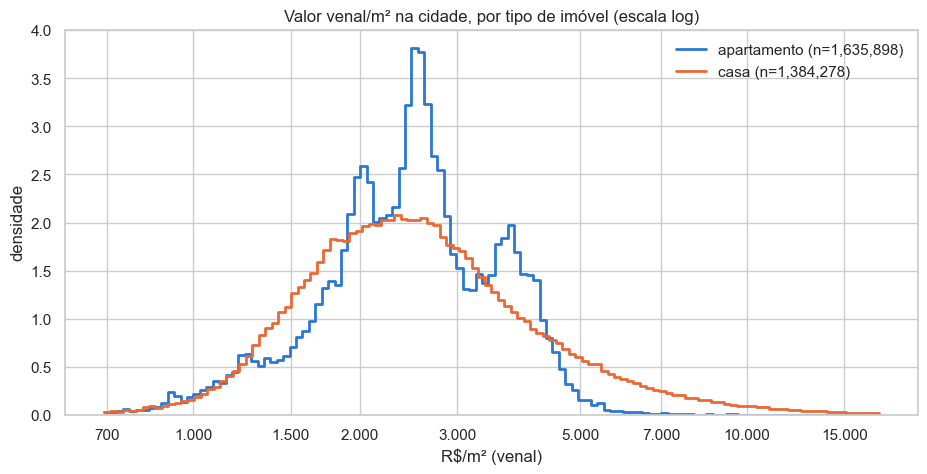

In [ ]:
def eixo_reais(ax, axis="x"):
    """Os dados estão em log10; este formatter mostra no eixo o valor em R$ (10**v) com ponto de milhar."""
    fmt = mticker.FuncFormatter(lambda v, _: f"{10**v:,.0f}".replace(",", "."))
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)

fig, ax = plt.subplots(figsize=(11, 5))
# um histograma por tipo; stat="density" normaliza cada curva para área 1, assim dá para comparar
# as formas mesmo com quantidades muito diferentes de apartamentos e casas
for tipo, cor in (("apartamento", AZUL), ("casa", LARANJA)):
    sns.histplot(r.loc[r["tipo"] == tipo, "log_m2"], bins=120, stat="density", element="step",
                 fill=False, linewidth=2, color=cor, label=f"{tipo} (n={(r['tipo'] == tipo).sum():,})", ax=ax)
ax.set_xticks(np.log10([700, 1000, 1500, 2000, 3000, 5000, 7000, 10000, 15000]))   # ticks em valores "redondos" de R$
eixo_reais(ax)
ax.set(title="Valor venal/m² na cidade, por tipo de imóvel (escala log)", xlabel="R$/m² (venal)", ylabel="densidade")
ax.legend(frameon=False)
plt.show()

## 3. Detecção de multimodalidade

In [ ]:
# grade comum de pontos (em log10) onde todas as densidades são avaliadas -> curvas comparáveis entre distritos
GRID = np.linspace(r["log_m2"].min(), r["log_m2"].max(), 600)
rng = np.random.default_rng(42)   # semente fixa: a amostragem (e portanto os resultados) é reprodutível
AMOSTRA = 20_000

def amostra(x):
    """Subamostra até 20 mil valores: o gaussian_kde é O(n × pontos da grade) e 20 mil já definem bem a forma."""
    return x if len(x) <= AMOSTRA else rng.choice(x, AMOSTRA, replace=False)

# KDE de cada distrito (usado no ridgeline da seção 4)
kde = {d: gaussian_kde(amostra(g.values))(GRID) for d, g in r.groupby("distrito")["log_m2"]}
# resumo "de um número só" que estamos questionando: média e mediana por distrito (em R$/m², não em log)
resumo = r.groupby("distrito").agg(n=("venal_m2", "size"), media=("venal_m2", "mean"),
                                   mediana=("venal_m2", "median"), regiao=("regiao", "first"))

In [ ]:
# limiares do critério de multimodalidade (ver markdown acima)
#   PROEMINENCIA: um pico só conta se "se destaca" pelo menos 10% da altura máxima do KDE
#   D_MIN:        separação mínima (D de Ashman) entre as duas gaussianas
#   PESO_MIN:     o grupo menor precisa ter pelo menos 10% dos imóveis
PROEMINENCIA, D_MIN, PESO_MIN = 0.10, 2.0, 0.10

def diagnostico(x, grid=None):
    """Recebe os valores (em log10) de um grupo e devolve as métricas dos dois critérios."""
    grid = GRID if grid is None else grid
    xs = amostra(x)

    # --- critério 1: picos do KDE ---
    # estima a densidade e conta os máximos locais; a proeminência mede quanto o pico sobe acima do
    # "vale" que o separa do pico vizinho, então ondulações pequenas (ruído) são descartadas
    dens = gaussian_kde(xs)(grid)
    picos, _ = find_peaks(dens, prominence=PROEMINENCIA * dens.max())

    # --- critério 2: mistura de 2 gaussianas (GMM) ---
    # n_init=3: roda o EM 3 vezes com inicializações diferentes e fica com o melhor ajuste
    gm = GaussianMixture(2, n_init=3, random_state=0).fit(xs.reshape(-1, 1))
    # ordena as componentes pela média, para que a componente 0 seja sempre o modo baixo e a 1 o modo alto
    ordem = np.argsort(gm.means_.ravel())
    mu, sd, w = gm.means_.ravel()[ordem], np.sqrt(gm.covariances_.ravel())[ordem], gm.weights_[ordem]
    # D de Ashman: distância entre as médias medida em "desvios-padrão combinados".
    # D > 2 => as duas gaussianas são separadas o suficiente para a soma ter dois picos (bimodal de verdade);
    # D pequeno => as duas componentes se sobrepõem e só estão modelando assimetria/cauda.
    D = np.sqrt(2) * abs(mu[1] - mu[0]) / np.sqrt(sd[0]**2 + sd[1]**2)

    return pd.Series({"n_picos": len(picos),
                      "modos_kde": np.round(10**grid[picos], -1).astype(int).tolist(),   # posição dos picos em R$/m²
                      "ashman_D": D, "peso_menor": w.min(),
                      "modo1": 10**mu[0], "modo2": 10**mu[1], "peso1": w[0], "peso2": w[1],   # de volta para R$/m²
                      "_gmm": (mu, sd, w)})   # parâmetros crus, guardados para desenhar as gaussianas depois

# aplica o diagnóstico em cada distrito; unstack transforma a Series de Series em colunas
diag = r.groupby("distrito")["log_m2"].apply(lambda s: diagnostico(s.values)).unstack()
diag = resumo.join(diag)
# regra final: só é multimodal se os DOIS critérios concordam
#   (KDE com ≥ 2 picos) E (gaussianas bem separadas) E (grupo menor não é uma caudinha)
diag["multimodal"] = (diag["n_picos"] >= 2) & (diag["ashman_D"] > D_MIN) & (diag["peso_menor"] >= PESO_MIN)

# mostra quantos distritos cada critério pegaria sozinho, para ver o efeito de exigir os dois
print(f"distritos multimodais: {diag['multimodal'].sum()} de {len(diag)}")
print(f"  só ≥2 picos no KDE: {(diag['n_picos'] >= 2).sum()} | só GMM (D>2 e peso≥10%): "
      f"{((diag['ashman_D'] > D_MIN) & (diag['peso_menor'] >= PESO_MIN)).sum()}")

distritos multimodais: 6 de 96
  só ≥2 picos no KDE: 23 | só GMM (D>2 e peso≥10%): 8


## 4. Distribuição por distrito: ridgeline por região

Uma curva de densidade (KDE em log10) por distrito, ordenadas pela mediana. A linha vertical marca a
**mediana** (o valor que hoje vai para `distrito_features.csv`) e o losango marca a **média**.
Distritos em laranja são os sinalizados como multimodais na seção 3.

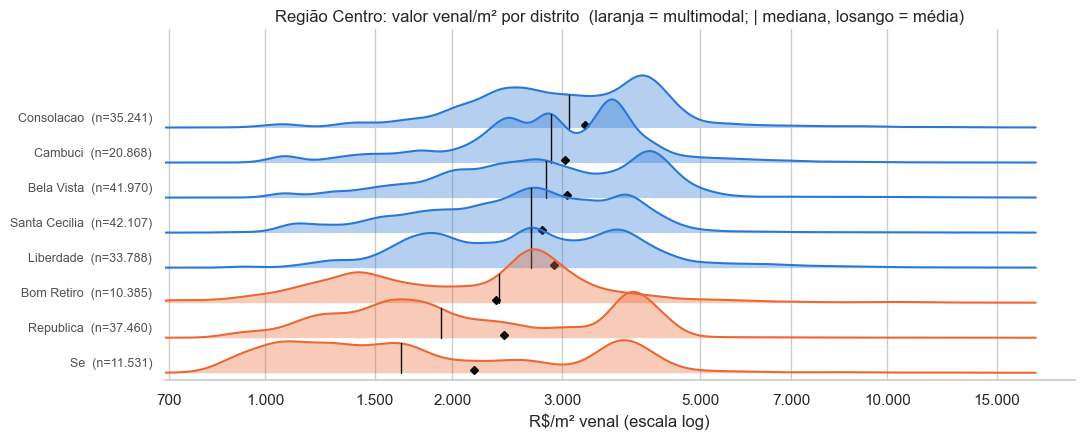

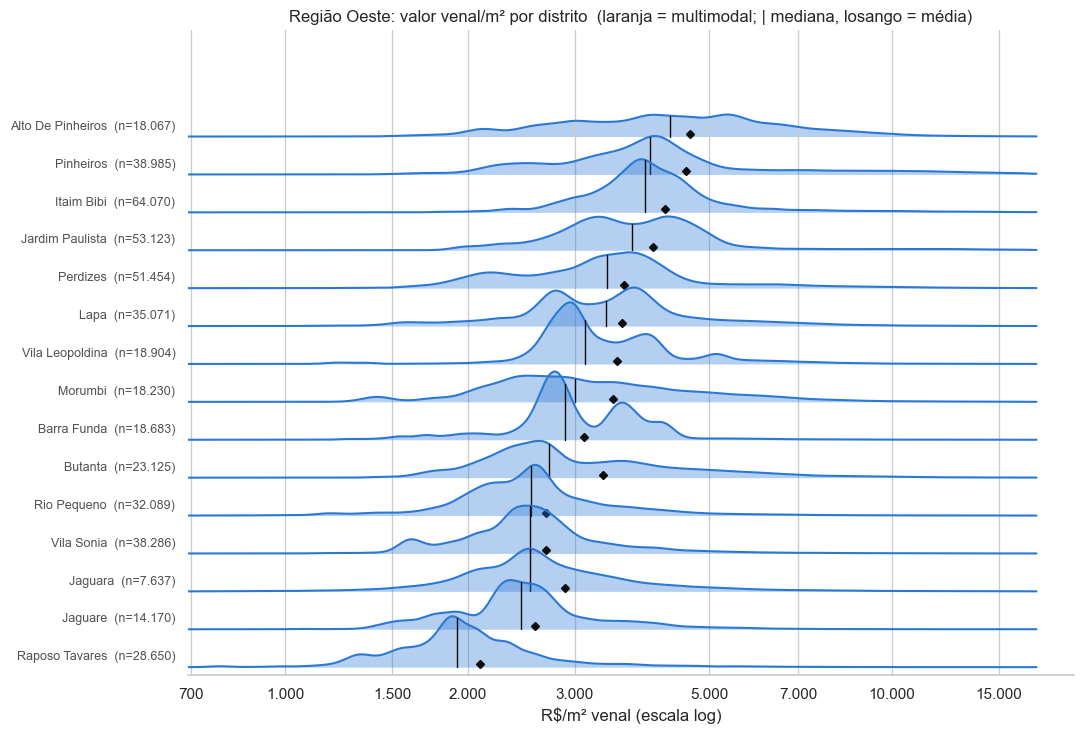

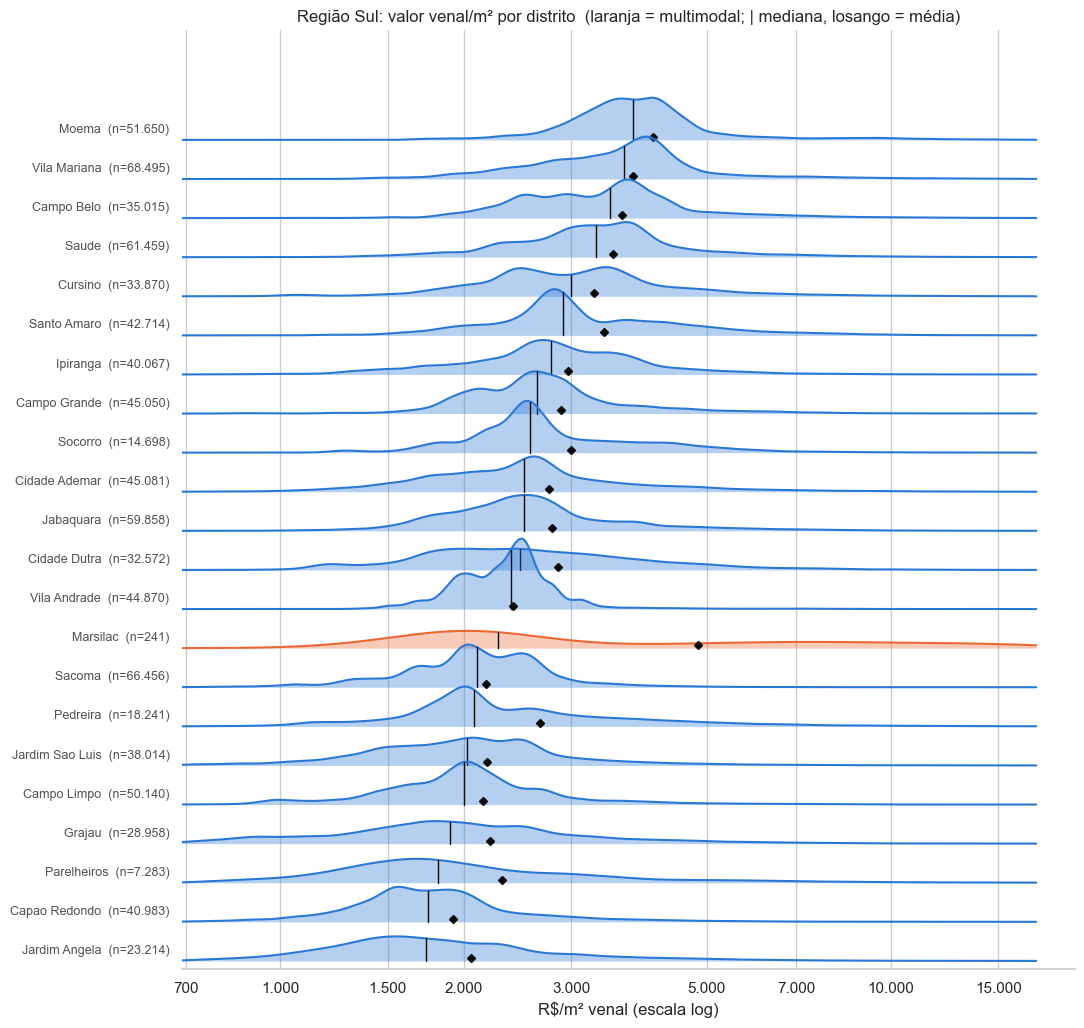

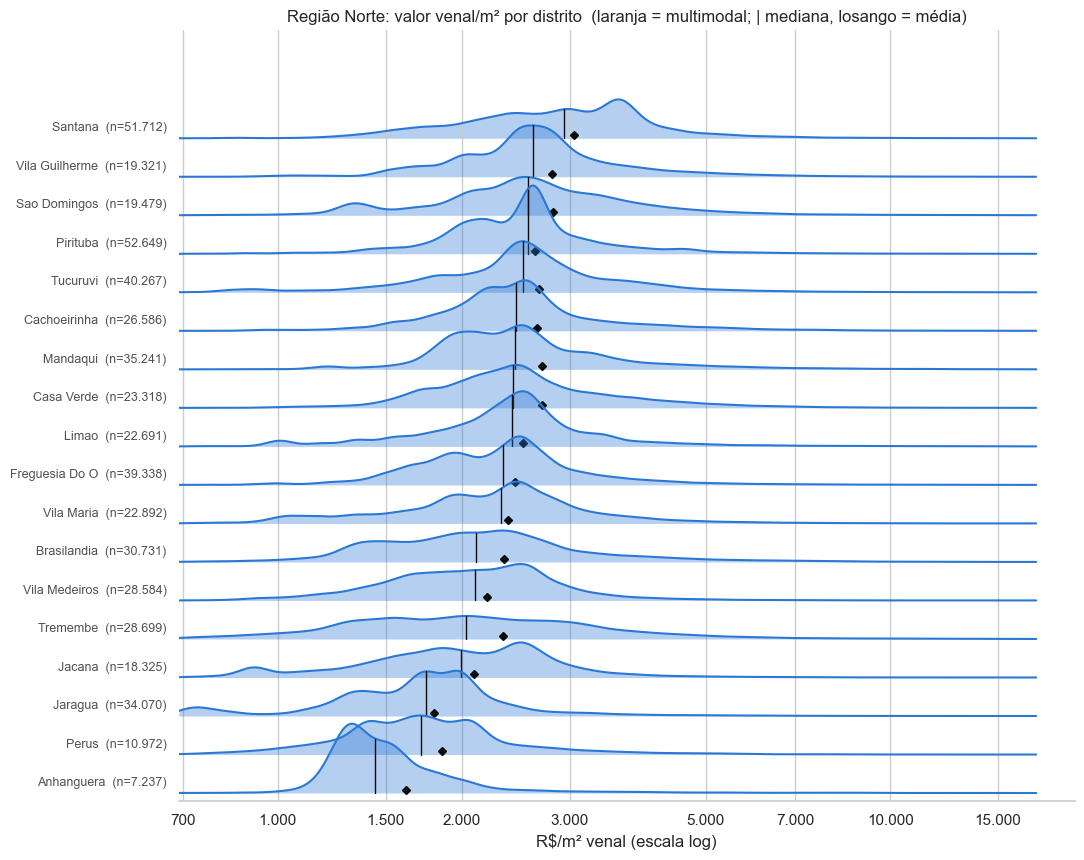

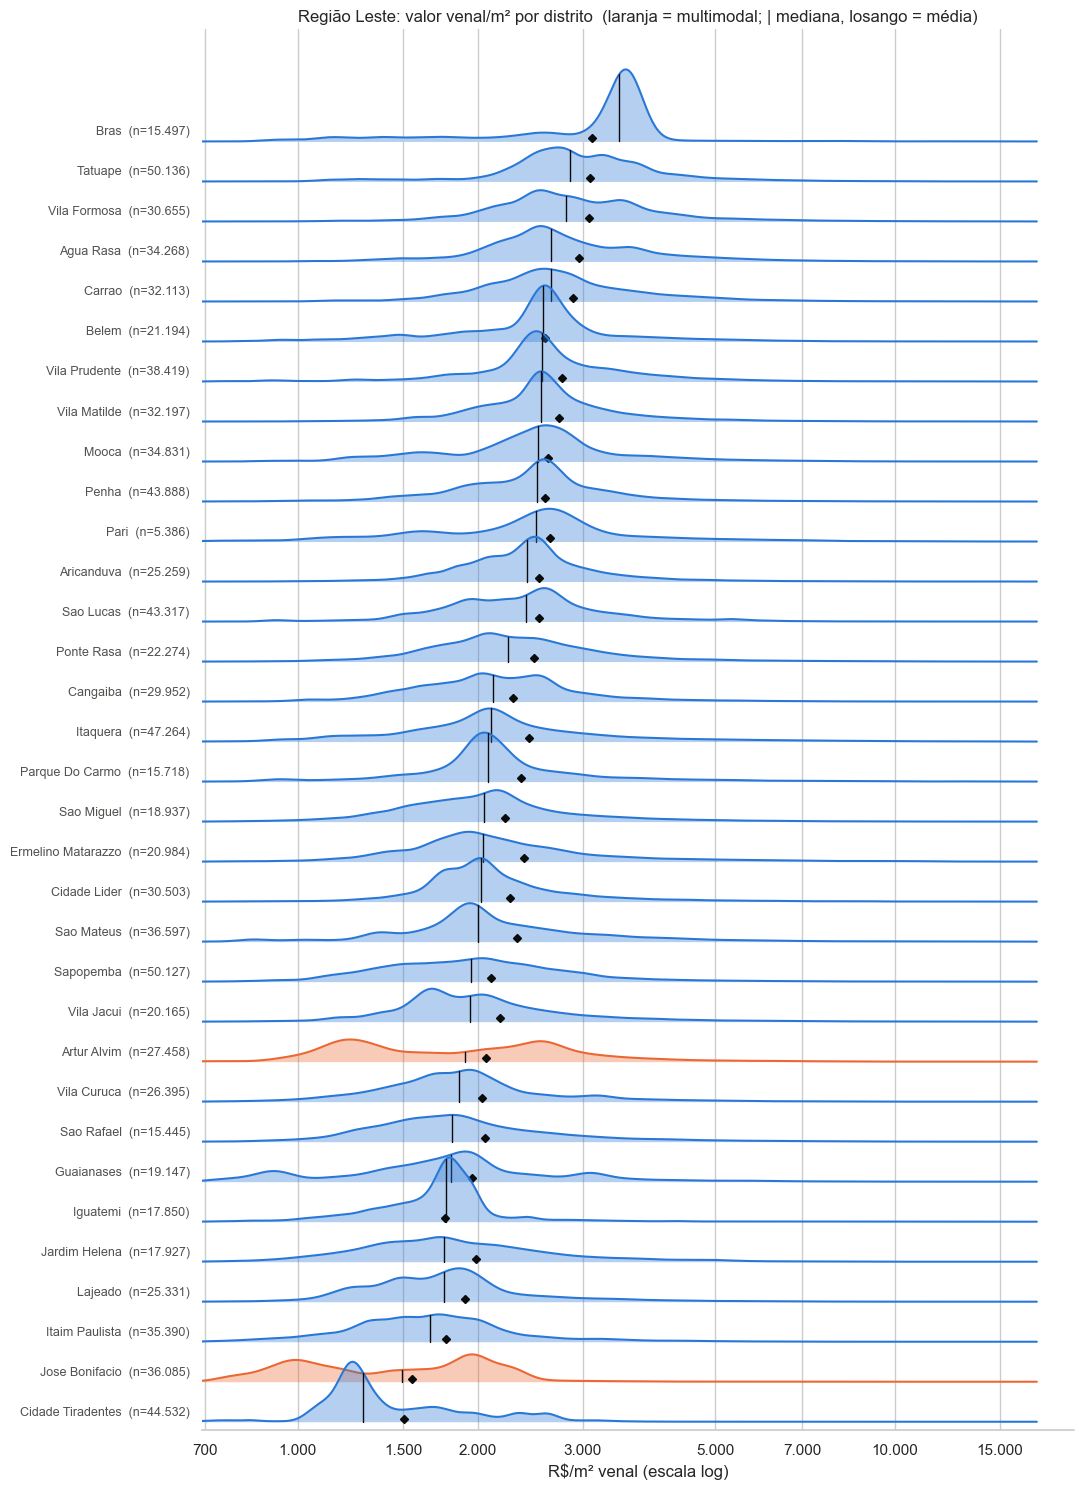

In [ ]:
TICKS = np.log10([700, 1000, 1500, 2000, 3000, 5000, 7000, 10000, 15000])

def ridgeline(distritos, titulo, sobreposicao=1.8, kde_=None, diag_=None, grid=None, ticks=None,
              xmax=np.log10(20000), xlabel="R$/m² venal (escala log)"):
    """Uma curva de densidade por distrito, empilhadas verticalmente (cada uma numa "linha" y0).

    Por padrão usa as variáveis globais do venal/m² (kde, diag, GRID, TICKS); os parâmetros
    kde_/diag_/grid/ticks permitem reaproveitar a função para o terreno/m² na seção 7.
    """
    kde, diag, GRID = (kde_ if kde_ is not None else globals()["kde"], diag_ if diag_ is not None else globals()["diag"],
                       grid if grid is not None else globals()["GRID"])
    TICKS = ticks if ticks is not None else globals()["TICKS"]
    distritos = list(distritos)
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(distritos) + 1.2))
    # mesma escala para todas as curvas (pela maior densidade): alturas comparáveis entre distritos
    escala = max(kde[d].max() for d in distritos)
    for i, d in enumerate(distritos):
        y0 = len(distritos) - 1 - i   # primeiro distrito da lista fica no topo
        dens = kde[d] / escala * sobreposicao   # sobreposicao > 1 deixa as curvas invadirem a linha de cima
        cor = LARANJA if diag.at[d, "multimodal"] else AZUL
        # zorder crescente: cada curva é desenhada por cima da anterior (efeito "cordilheira")
        ax.fill_between(GRID, y0, y0 + dens, color=cor, alpha=0.35, linewidth=0, zorder=2 * i)
        ax.plot(GRID, y0 + dens, color=cor, linewidth=1.5, zorder=2 * i + 1)
        # mediana = traço vertical até a curva; média = losango na base
        med, mea = np.log10(diag.at[d, "mediana"]), np.log10(diag.at[d, "media"])
        ax.plot([med, med], [y0, y0 + np.interp(med, GRID, dens)], color="#0b0b0b", linewidth=1, zorder=2 * i + 1)
        ax.plot(mea, y0 + 0.08, marker="D", markersize=4, color="#0b0b0b", zorder=2 * i + 1)
        ax.text(GRID[0] - 0.02, y0 + 0.1, f"{d.title()}  (n={diag.at[d, 'n']:,})".replace(",", "."),
                ha="right", va="bottom", fontsize=9, color="#52514e")
    ax.set_yticks([]); ax.set_xticks(TICKS); eixo_reais(ax)
    ax.set_xlim(GRID[0], xmax); ax.set_ylim(-0.2, len(distritos) + sobreposicao)
    ax.set(title=titulo, xlabel=xlabel)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, left=True)
    plt.tight_layout(); plt.show()

# um gráfico por região, distritos do mais caro (topo) ao mais barato (mediana)
for reg in ["Centro", "Oeste", "Sul", "Norte", "Leste"]:
    ds = diag[diag["regiao"] == reg].sort_values("mediana", ascending=False).index
    ridgeline(ds, f"Região {reg}: valor venal/m² por distrito  (laranja = multimodal; | mediana, losango = média)")

### Tabela: distritos multimodais

In [ ]:
# tabela dos distritos que passaram nos dois critérios, do mais separado (maior D) para o menos
cols = ["regiao", "n", "media", "mediana", "modos_kde", "modo1", "peso1", "modo2", "peso2", "ashman_D"]
tab_multi = diag.loc[diag["multimodal"], cols].sort_values("ashman_D", ascending=False)
tab_multi.style.format({"media": "{:,.0f}", "mediana": "{:,.0f}", "modo1": "{:,.0f}", "modo2": "{:,.0f}",
                        "peso1": "{:.0%}", "peso2": "{:.0%}", "ashman_D": "{:.2f}", "n": "{:,}"})

,regiao,n,media,mediana,modos_kde,modo1,peso1,modo2,peso2,ashman_D
distrito,,,,,,,,,,
MARSILAC,Sul,241,"4,834","2,271","[2020, 7400]","1,994",58%,"7,812",42%,3.91
SE,Centro,"11,531","2,164","1,653","[1090, 3780]","1,316",63%,"3,420",37%,3.66
JOSE BONIFACIO,Leste,"36,085","1,551","1,492","[990, 1960]",994,41%,"1,882",59%,3.41
REPUBLICA,Centro,"37,460","2,417","1,916","[1650, 3900]","1,740",73%,"3,955",27%,3.36
BOM RETIRO,Centro,"10,385","2,353","2,375","[1420, 2710]","1,321",36%,"2,751",64%,2.61
ARTUR ALVIM,Leste,"27,458","2,070","1,906","[1230, 2550]","1,209",32%,"2,304",68%,2.35


### Detalhe dos multimodais: histograma + as duas gaussianas

Para cada distrito sinalizado: o histograma (log), as duas componentes do GMM (azul e laranja) e as linhas
da **média** (tracejada) e da **mediana** (contínua). Quando elas caem entre os dois picos, o resumo de um número
só não representa nenhum dos dois grupos.

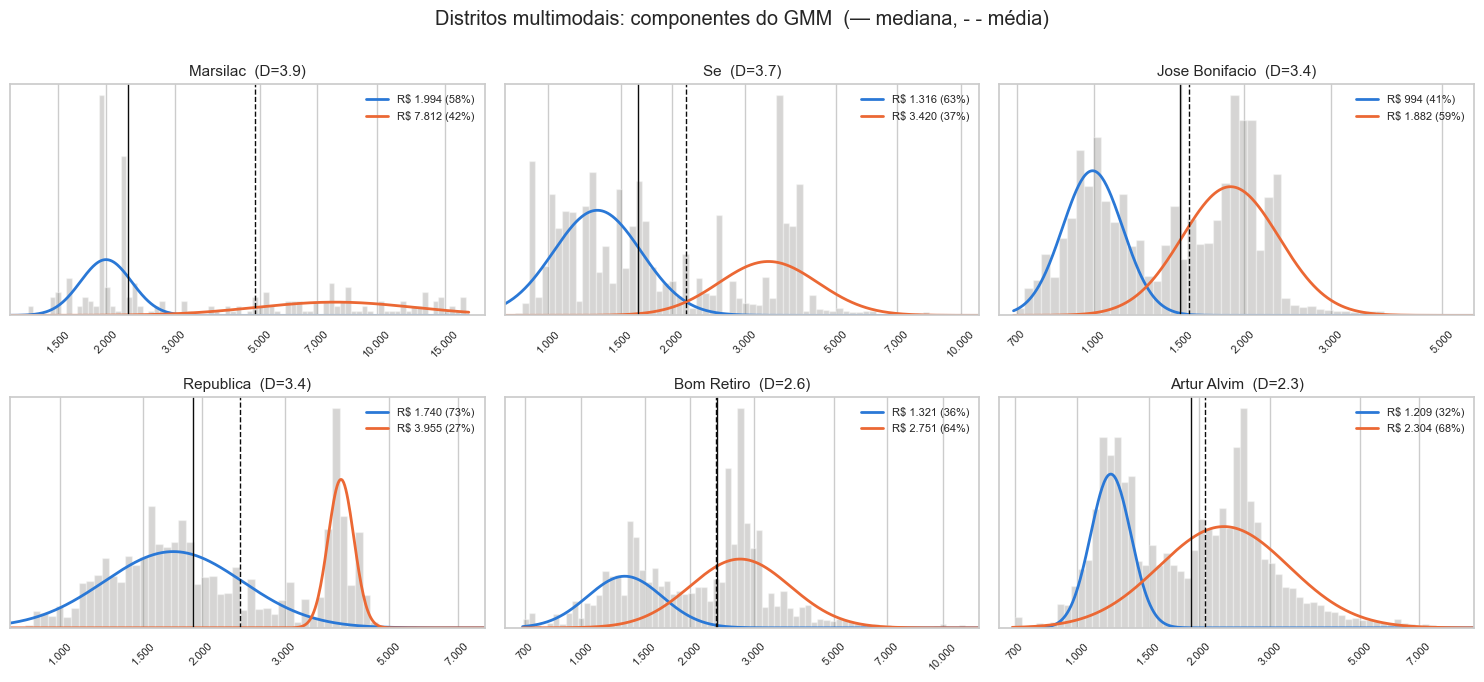

In [ ]:
def painel_gmm(distritos, ncols=3, col="log_m2", diag_=None, grid=None, ticks=None,
               titulo="Distritos multimodais: componentes do GMM  (— mediana, - - média)"):
    """Grade de painéis: histograma do distrito + as duas gaussianas ajustadas pelo GMM.

    Serve para conferir visualmente o diagnóstico: se as duas curvas coloridas cobrem dois "morros"
    distintos do histograma, a bimodalidade é real; se se sobrepõem, o GMM só está modelando cauda.
    """
    diag, GRID = (diag_ if diag_ is not None else globals()["diag"], grid if grid is not None else globals()["GRID"])
    TICKS = ticks if ticks is not None else globals()["TICKS"]
    distritos = list(distritos)
    nrows = int(np.ceil(len(distritos) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows), squeeze=False)
    for ax, d in zip(axes.flat, distritos):
        x = r.loc[r["distrito"] == d, col].dropna()
        ax.hist(x, bins=80, density=True, color=CINZA, alpha=0.35)
        mu, sd, w = diag.at[d, "_gmm"]
        # cada componente é desenhada multiplicada pelo seu peso: a soma das duas curvas reproduz a mistura
        for k, cor in enumerate((AZUL, LARANJA)):
            ax.plot(GRID, w[k] * norm.pdf(GRID, mu[k], sd[k]), color=cor, linewidth=2,
                    label=f"R$ {10**mu[k]:,.0f} ({w[k]:.0%})".replace(",", "."))
        # média (tracejada) e mediana (contínua): queremos ver se caem no vale entre as duas gaussianas
        ax.axvline(np.log10(diag.at[d, "media"]), color="#0b0b0b", linestyle="--", linewidth=1)
        ax.axvline(np.log10(diag.at[d, "mediana"]), color="#0b0b0b", linewidth=1)
        ax.set_xticks(TICKS); eixo_reais(ax); ax.tick_params(axis="x", labelsize=8, rotation=45)
        ax.set_xlim(x.quantile(0.002) - 0.05, x.quantile(0.998) + 0.05)   # zoom no intervalo onde há dados
        ax.set_title(f"{d.title()}  (D={diag.at[d, 'ashman_D']:.1f})", fontsize=11)
        ax.set_yticks([]); ax.legend(frameon=False, fontsize=8)
    for ax in axes.flat[len(distritos):]:   # esconde painéis vazios da última linha
        ax.axis("off")
    fig.suptitle(titulo, y=1.0)
    plt.tight_layout(); plt.show()

painel_gmm(tab_multi.index)